# Segundo Parcial PLN II/2026 — Clasificación automática de comentarios universitarios

**Problema de investigación:** ¿Qué representación de los textos (BoW o TF-IDF) y qué algoritmo de clasificación (Naive Bayes o SVM) obtienen mejores resultados al clasificar automáticamente comentarios?
<hr>
<h1>FASE 1 — Preparación y exploración de los datos
<h4>Rúbrica: Preparación de los datos (10 pts) → limpieza, etiquetas y separación correcta.
<hr>

### Índice general del notebook
| Fase | Contenido | Rúbrica |
|---|---|---|
| 1 | Preparación y exploración (carga, limpieza con diccionario propio, split 80/20) | 10 pts |
| 2 | Bag of Words y TF-IDF | 10 + 15 pts |
| 3 | PCA (varianza explicada, gráfico 2D, interpretación) | 15 pts |
| 4 | Naive Bayes y SVM con BoW y TF-IDF (4 modelos, mismo test) | 20 pts |
| 5 | Análisis crítico (errores, 5 comentarios nuevos, elección del modelo, mejoras, 7 preguntas) | 20 pts |
| — | Código organizado, semillas fijas, resultados y conclusiones | 10 pts |



## 1.1 Configuración y reproducibilidad

In [13]:
import re
import sys
import random
import unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import nltk
from nltk.stem import SnowballStemmer
from sklearn.model_selection import train_test_split

# ----------------------------- PARÁMETROS EDITABLES -----------------------------
RUTA_EXCEL      = "../data/comentarios.xlsx"   # <-- ruta del archivo Excel
HOJA            = 0                         # nombre o índice de la hoja
COL_TEXTO       = "comentario"
COL_ETIQUETA    = "categoria"
SEMILLA         = 42
TAM_PRUEBA      = 0.20                      # 80% entrenamiento / 20% prueba
DIR_ARTEFACTOS  = Path("artefactos")
# --------------------------------------------------------------------------------

random.seed(SEMILLA)
np.random.seed(SEMILLA)
DIR_ARTEFACTOS.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 90)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | nltk {nltk.__version__}")

Python 3.13.2 | pandas 2.2.3 | scikit-learn 1.6.1 | nltk 3.9.1


## 1.2 Carga del conjunto de datos
El corpus es una hoja de Excel con dos columnas: `comentario` y `categoria` (positiva / negativa).

In [27]:
df_raw = pd.read_excel(RUTA_EXCEL)
df_raw.columns = [str(c).strip().lower() for c in df_raw.columns]

faltan = {COL_TEXTO, COL_ETIQUETA} - set(df_raw.columns)
assert not faltan, f"Faltan columnas en el Excel: {faltan}. Columnas encontradas: {list(df_raw.columns)}"

df_raw = df_raw[[COL_TEXTO, COL_ETIQUETA]].copy()
print(f"Filas cargadas: {len(df_raw)}")
df_raw.head(10)

Filas cargadas: 120


,comentario,categoria
0,La docente explicó el tema con ejemplos claros y fáciles de comprender.,Positivo
1,La plataforma virtual funciona bien y permite entregar tareas sin problemas.,Positivo
2,El proceso de inscripción fue rápido y sencillo.,Positivo
3,La biblioteca tiene libros útiles y espacios cómodos para estudiar.,Positivo
4,El personal administrativo respondió amablemente a mis consultas.,Positivo
5,Las prácticas de laboratorio ayudaron a comprender la teoría.,Positivo
6,El profesor publicó las calificaciones dentro del plazo establecido.,Positivo
7,Las aulas están limpias y cuentan con buena iluminación.,Positivo
8,El sistema de inscripción en línea ahorró mucho tiempo.,Positivo
9,La universidad ofrece talleres interesantes para complementar las materias.,Positivo


## 1.3 Validación de calidad de los datos
Antes de dividir se verifica que no existan problemas que contaminen la evaluación:
- **Nulos o textos vacíos** → se eliminan.
- **Etiquetas** → se normalizan a `positiva` / `negativa` (se tolera mayúsculas, tildes, espacios y variantes como "positivo").
- **Duplicados exactos** → se eliminan. Si un mismo comentario estuviera en *train* y en *test*, la evaluación estaría inflada (fuga de datos).
- **Contradicciones** (mismo texto con etiquetas distintas) → se eliminan, porque no hay una etiqueta confiable.

In [28]:
def sin_tildes(s: str) -> str:
    # Quita tildes conservando la ñ.
    s = s.replace("ñ", "\x00").replace("Ñ", "\x01")
    s = "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")
    return s.replace("\x00", "ñ").replace("\x01", "Ñ")

def normalizar_etiqueta(x):
    if pd.isna(x):
        return np.nan
    e = sin_tildes(str(x)).strip().lower()
    if e.startswith("pos"):
        return "positiva"
    if e.startswith("neg"):
        return "negativa"
    if e.startswith("con"):
        return "consulta"
    return e  # se reporta abajo si es una categoría inesperada

df = df_raw.copy()
registro = {"filas_iniciales": len(df)}

# 1) Nulos y textos vacíos
df[COL_TEXTO] = df[COL_TEXTO].astype("string").str.strip()
mask_vacio = df[COL_TEXTO].isna() | (df[COL_TEXTO] == "") | df[COL_ETIQUETA].isna()
registro["nulos_o_vacios"] = int(mask_vacio.sum())
df = df[~mask_vacio].copy()

# 2) Etiquetas
df[COL_ETIQUETA] = df[COL_ETIQUETA].map(normalizar_etiqueta)
categorias = sorted(df[COL_ETIQUETA].unique())
print("Categorías encontradas:", categorias)
assert set(categorias) <= {"positiva", "negativa","consulta"}, (
    f"Hay etiquetas inesperadas: {set(categorias) - {'positiva', 'negativa'}}. Revisa el Excel.")

# 3) Contradicciones y duplicados (se comparan en minúsculas y sin espacios extra)
df["_clave"] = df[COL_TEXTO].str.lower().str.replace(r"\s+", " ", regex=True)
n_etiq = df.groupby("_clave")[COL_ETIQUETA].nunique()
claves_contradictorias = n_etiq[n_etiq > 1].index
registro["contradictorios"] = int(df["_clave"].isin(claves_contradictorias).sum())
df = df[~df["_clave"].isin(claves_contradictorias)]

registro["duplicados_exactos"] = int(df.duplicated("_clave").sum())
df = df.drop_duplicates("_clave").drop(columns="_clave").reset_index(drop=True)
registro["filas_finales"] = len(df)

pd.DataFrame(registro, index=["cantidad"]).T

Categorías encontradas: ['consulta', 'negativa', 'positiva']


,cantidad
filas_iniciales,120
nulos_o_vacios,0
contradictorios,0
duplicados_exactos,0
filas_finales,120


## 1.4 Exploración: balance de clases y longitud de los comentarios

,comentarios,porcentaje
categoria,,
positiva,40,33.3
negativa,40,33.3
consulta,40,33.3


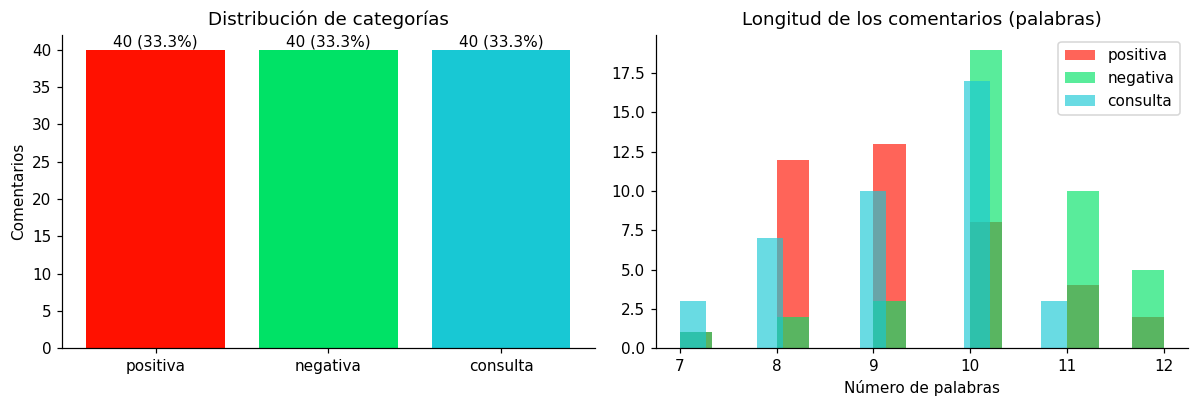

,count,mean,std,min,25%,50%,75%,max
categoria,,,,,,,,
consulta,40.0,9.2,1.1,7.0,8.8,9.5,10.0,11.0
negativa,40.0,10.2,1.1,7.0,10.0,10.0,11.0,12.0
positiva,40.0,9.2,1.2,7.0,8.0,9.0,10.0,12.0


✔ Corpus razonablemente balanceado (razón 1.00:1).


In [32]:
conteo = df[COL_ETIQUETA].value_counts()
porc = (conteo / conteo.sum() * 100).round(1)
display(pd.DataFrame({"comentarios": conteo, "porcentaje": porc}))

df["n_palabras"] = df[COL_TEXTO].str.split().str.len()
df["n_caracteres"] = df[COL_TEXTO].str.len()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
colores = {"positiva": "#ff1100", "negativa": "#00e266", "consulta": "#18c8d4"}

ax[0].bar(conteo.index, conteo.values, color=[colores[c] for c in conteo.index])
for i, (c, v) in enumerate(conteo.items()):
    ax[0].text(i, v, f"{v} ({porc[c]}%)", ha="center", va="bottom")
ax[0].set_title("Distribución de categorías")
ax[0].set_ylabel("Comentarios")

for c in conteo.index:
    ax[1].hist(df.loc[df[COL_ETIQUETA] == c, "n_palabras"], bins=15, alpha=.65,
               label=c, color=colores[c])
ax[1].set_title("Longitud de los comentarios (palabras)")
ax[1].set_xlabel("Número de palabras")
ax[1].legend()
plt.tight_layout()
plt.show()

display(df.groupby(COL_ETIQUETA)["n_palabras"].describe().round(1))

razon = conteo.max() / conteo.min()
if razon > 1.5:
    print(f"⚠ Corpus desbalanceado (razón {razon:.2f}:1). Accuracy puede engañar: "
          "en las fases 4-5 se priorizará F1 macro, recall por clase y class_weight.")
else:
    print(f"✔ Corpus razonablemente balanceado (razón {razon:.2f}:1).")

## 1.5 Diccionario propio y tratamiento de *stop words*



1. **Diccionario propio** de normalización: abreviaturas, jerga de chat y errores ortográficos frecuentes.
2. **Stop words del español** (NLTK) **conservando las palabras de negación y contraste** (`no`, `nunca`, `sin`, `pero`, …), porque en análisis de sentimiento "no me gustó" y "me gustó" son opuestos.
3. **Stemming** con `SnowballStemmer('spanish')` (algoritmo basado en reglas, no neuronal).
4. **Marcado de negación:** `no` + palabra siguiente → un solo token (`no_gust`), para que BoW/TF-IDF distingan "bueno" de "no bueno".

> **Decisión sobre la puntuación:** se elimina, pero se conservan como tokens los **emojis/emoticones** más comunes, que en comentarios en línea portan polaridad.

In [33]:
# ---------------------- Diccionario propio (editable y ampliable) ----------------------
# Claves en minúsculas y SIN tildes (se aplican después de normalizar el texto).
DICCIONARIO_PROPIO = {
    # abreviaturas y jerga de chat
    "q": "que", "xq": "porque", "pq": "porque", "porq": "porque", "x": "por", "xa": "para",
    "pa": "para", "tb": "tambien", "tmb": "tambien", "tbn": "tambien", "d": "de", "k": "que",
    "bn": "bien", "ntp": "no_hay_problema", "grax": "gracias", "gracias": "gracias",
    "dnd": "donde", "cmo": "como", "kien": "quien", "sii": "si", "sip": "si", "nop": "no",
    "toy": "estoy", "ta": "esta", "pk": "porque",
    # términos universitarios frecuentes
    "profe": "profesor", "profes": "profesores", "prof": "profesor", "docentes": "docente",
    "uni": "universidad", "univ": "universidad", "umsa": "universidad",
    "mate": "matematica", "mates": "matematica", "info": "informacion", "inscrip": "inscripcion",
    "inscripciones": "inscripcion", "bibliot": "biblioteca", "lab": "laboratorio",
    "labs": "laboratorio", "wifi": "internet", "wi-fi": "internet",
    # errores ortográficos frecuentes (sin tilde)
    "exelente": "excelente", "ecxelente": "excelente", "exelentes": "excelente",
    "pesimo": "pesimo", "pecimo": "pesimo", "orible": "horrible", "orrible": "horrible",
    "aburrio": "aburrido", "aburida": "aburrida", "vien": "bien", "muybien": "muy bien",
    "agradeser": "agradecer", "ermoso": "hermoso", "aser": "hacer", "haser": "hacer",
    "atencion": "atencion", "atension": "atencion", "atencon": "atencion",
    "deficiente": "deficiente", "deficiensia": "deficiencia", "tardansa": "tardanza",
    "nesesito": "necesito", "nesecito": "necesito", "buenizimo": "buenisimo",
}

EMOJIS = {
    "positivo": ["😀", "😃", "😄", "😁", "😊", "🙂", "😍", "👍", "👏", "❤", "💯", "🎉", "😎", "🥰"],
    "negativo": ["😡", "😠", "😞", "😢", "😭", "👎", "💔", "😤", "🤬", "😒", "😩", "😫"],
}
EMOTICONES = {r":\)": "emopos", r":-\)": "emopos", r":d\b": "emopos", r":\(": "emoneg", r":-\(": "emoneg"}

# ---------------------------- Stop words con excepciones ----------------------------
try:
    from nltk.corpus import stopwords
    STOP_BASE = set(stopwords.words("spanish"))
except LookupError:
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords
    STOP_BASE = set(stopwords.words("spanish"))

# Palabras que NO se eliminan porque cambian o invierten el sentido
NEGADORES = {"no", "nunca", "jamas", "tampoco", "sin", "ni"}
CONSERVAR = NEGADORES | {"pero", "aunque", "sino", "muy", "mas", "menos", "nada", "poco", "mucho",
                         "bien", "mal", "mejor", "peor", "todo", "algo"}

STOPWORDS = {sin_tildes(w) for w in STOP_BASE} - {sin_tildes(w) for w in CONSERVAR}
print(f"Stop words base NLTK: {len(STOP_BASE)} | efectivas tras excepciones: {len(STOPWORDS)}")
print("Conservadas (no se eliminan):", sorted(CONSERVAR))

Stop words base NLTK: 313 | efectivas tras excepciones: 295
Conservadas (no se eliminan): ['algo', 'aunque', 'bien', 'jamas', 'mal', 'mas', 'mejor', 'menos', 'mucho', 'muy', 'nada', 'ni', 'no', 'nunca', 'peor', 'pero', 'poco', 'sin', 'sino', 'tampoco', 'todo']


## 1.6 Función de limpieza y evidencia *antes → después*
La función `limpiar_texto` tiene dos modos para poder justificar cada decisión en el informe:
- `texto_limpio` → minúsculas, sin puntuación, diccionario, **sin stop words**, sin stemming (legible, útil para la exploración).
- `texto_proc` → además aplica **stemming y marcado de negación** (es el que usarán BoW/TF-IDF en la Fase 2).

In [34]:
STEMMER = SnowballStemmer("spanish")

def _emojis_a_tokens(t: str) -> str:
    for e in EMOJIS["positivo"]:
        t = t.replace(e, " emopos ")
    for e in EMOJIS["negativo"]:
        t = t.replace(e, " emoneg ")
    for patron, tok in EMOTICONES.items():
        t = re.sub(patron, f" {tok} ", t)
    return t

def limpiar_texto(texto: str, stem: bool = False, marcar_negacion: bool = False) -> str:
    # 1) minúsculas y emojis -> tokens
    t = _emojis_a_tokens(str(texto).lower())
    # 2) URLs, correos, menciones y números fuera
    t = re.sub(r"(https?://\S+|www\.\S+|\S+@\S+|[@#]\w+)", " ", t)
    t = re.sub(r"\d+", " ", t)
    # 3) sin tildes (conservando ñ)
    t = sin_tildes(t)
    # 4) alargamientos: "buenooooo" -> "bueno", "muuuy" -> "muy"
    t = re.sub(r"(.)\1{2,}", r"\1", t)
    # 5) puntuación fuera (se conservan letras, ñ y _ )
    t = re.sub(r"[^a-zñ_\s]", " ", t)
    tokens = t.split()
    # 6) diccionario propio (abreviaturas, jerga, ortografía)
    nuevos = []
    for tok in tokens:
        nuevos.extend(DICCIONARIO_PROPIO.get(tok, tok).split())
    # 7) stop words (conservando negaciones) y tokens de 1 letra
    tokens = [w for w in nuevos if w not in STOPWORDS and len(w) > 1]
    # 8) stemming
    if stem:
        tokens = [w if w in NEGADORES or w in ("emopos", "emoneg") else STEMMER.stem(w) for w in tokens]
    # 9) marcado de negación: "no" + palabra -> "no_palabra"
    if marcar_negacion:
        res, i = [], 0
        while i < len(tokens):
            if tokens[i] in NEGADORES and i + 1 < len(tokens) and tokens[i + 1] not in NEGADORES:
                res.append(f"{tokens[i]}_{tokens[i + 1]}")
                i += 2
            else:
                res.append(tokens[i])
                i += 1
        tokens = res
    return " ".join(tokens)

# Aplicación al corpus completo (el preprocesamiento es determinista y no "aprende" de los datos,
# por lo que aplicarlo antes del split NO produce fuga de datos).
df["texto_limpio"] = df[COL_TEXTO].apply(limpiar_texto)
df["texto_proc"]   = df[COL_TEXTO].apply(lambda s: limpiar_texto(s, stem=True, marcar_negacion=True))

# Se descartan comentarios que queden vacíos tras la limpieza
vacios = (df["texto_proc"].str.strip() == "")
print(f"Comentarios que quedan vacíos tras la limpieza: {int(vacios.sum())}")
df = df[~vacios].reset_index(drop=True)

# ---- Evidencia: pruebas unitarias del tratamiento de negación y diccionario ----
print("Prueba de negación →", limpiar_texto("No me gustó la atención", stem=True, marcar_negacion=True))
print("Prueba de jerga     →", limpiar_texto("Exelente profe!!! 😀", stem=False))

Comentarios que quedan vacíos tras la limpieza: 0
Prueba de negación → no_gust atencion
Prueba de jerga     → excelente profesor emopos


In [35]:
# Tabla "antes -> después" (evidencia para el informe)
muestra = df.sample(min(8, len(df)), random_state=SEMILLA)[[COL_TEXTO, "texto_limpio", "texto_proc", COL_ETIQUETA]]
muestra.columns = ["Original", "Limpio (sin stemming)", "Procesado (stem + negación)", "Categoría"]
muestra.reset_index(drop=True)

,Original,Limpio (sin stemming),Procesado (stem + negación),Categoría
0,En secretaría nadie respondió durante varios días a mi solicitud.,secretaria nadie respondio varios dias solicitud,secretari nadi respondi vari dias solicitud,negativa
1,El aula está sucia y varias luces no funcionan.,aula sucia varias luces no funcionan,aul suci vari luc no_funcion,negativa
2,El personal administrativo respondió amablemente a mis consultas.,personal administrativo respondio amablemente consultas,personal administr respondi amabl consult,positiva
3,La aplicación móvil muestra horarios que ya fueron modificados.,aplicacion movil muestra horarios modificados,aplic movil muestr horari modific,negativa
4,Las clases combinan teoría y práctica de manera equilibrada.,clases combinan teoria practica manera equilibrada,clas combin teori practic maner equilibr,positiva
5,No recibí orientación adecuada para elegir las materias del semestre.,no recibi orientacion adecuada elegir materias semestre,no_recibi orient adecu eleg materi semestr,negativa
6,Las aulas tienen demasiado ruido y cuesta escuchar al docente.,aulas demasiado ruido cuesta escuchar docente,aul demasi ruid cuest escuch docent,negativa
7,La tutora orientó al grupo durante todo el proyecto.,tutora oriento grupo todo proyecto,tutor orient grup tod proyect,positiva


In [36]:
# Efecto de la limpieza sobre el vocabulario
voc_original = {w for t in df[COL_TEXTO].str.lower() for w in re.findall(r"\w+", t)}
voc_limpio   = {w for t in df["texto_limpio"] for w in t.split()}
voc_proc     = {w for t in df["texto_proc"] for w in t.split()}

pd.DataFrame({
    "Vocabulario (tipos distintos)": [len(voc_original), len(voc_limpio), len(voc_proc)],
}, index=["Texto original", "Limpio (sin stop words)", "Procesado (stemming + negación)"])

,Vocabulario (tipos distintos)
Texto original,451
Limpio (sin stop words),397
Procesado (stemming + negación),317


## 1.7 Palabras más frecuentes por categoría
Exploración inicial de qué vocabulario caracteriza a cada clase (anticipa el análisis de BoW de la Fase 2).

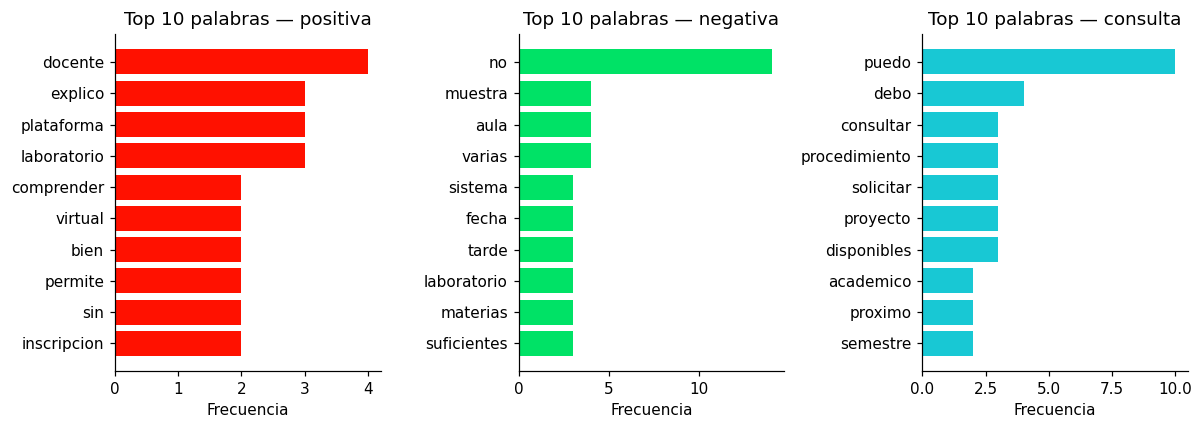

Palabras frecuentes en las clases (poco discriminantes): ['laboratorio', 'proyecto']


In [38]:
def top_palabras(serie, n=10):
    c = Counter(w for t in serie for w in t.split())
    return c.most_common(n)

fig, ax = plt.subplots(1, 3, figsize=(11, 4))
for a, cat in zip(ax, ["positiva", "negativa","consulta"]):
    if cat not in df[COL_ETIQUETA].values:
        continue
    pares = top_palabras(df.loc[df[COL_ETIQUETA] == cat, "texto_limpio"], 10)[::-1]
    a.barh([p[0] for p in pares], [p[1] for p in pares], color=colores[cat])
    a.set_title(f"Top 10 palabras — {cat}")
    a.set_xlabel("Frecuencia")
plt.tight_layout()
plt.show()

# Palabras compartidas por ambas clases entre las más frecuentes (candidatas a ser poco discriminantes)
top_pos = {w for w, _ in top_palabras(df.loc[df[COL_ETIQUETA] == "positiva", "texto_limpio"], 25)}
top_neg = {w for w, _ in top_palabras(df.loc[df[COL_ETIQUETA] == "negativa", "texto_limpio"], 25)}
top_consulta = {w for w, _ in top_palabras(df.loc[df[COL_ETIQUETA] == "consulta", "texto_limpio"], 25)}
print("Palabras frecuentes en las clases (poco discriminantes):", sorted(top_pos & top_neg & top_consulta))

## 1.8 Separación entrenamiento / prueba (80 % / 20 %)
- **Estratificada** (`stratify`) para conservar la proporción de categorías en ambos conjuntos.
- **Semilla fija** para que *todos* los modelos (BoW+NB, TF-IDF+NB, BoW+SVM, TF-IDF+SVM) se evalúen sobre **exactamente el mismo conjunto de prueba**.
- A partir de aquí **el conjunto de prueba no se toca** hasta la evaluación: los vectorizadores y el PCA se ajustarán **solo con entrenamiento**.

In [39]:
assert df[COL_ETIQUETA].value_counts().min() >= 2, "Cada categoría necesita al menos 2 comentarios para estratificar."

idx_train, idx_test = train_test_split(
    df.index, test_size=TAM_PRUEBA, stratify=df[COL_ETIQUETA], random_state=SEMILLA, shuffle=True
)
train_df = df.loc[idx_train].reset_index(drop=True)
test_df  = df.loc[idx_test].reset_index(drop=True)

resumen_split = pd.DataFrame({
    "Entrenamiento": train_df[COL_ETIQUETA].value_counts(),
    "Prueba": test_df[COL_ETIQUETA].value_counts(),
})
resumen_split.loc["TOTAL"] = resumen_split.sum()
resumen_split["% Entrenamiento"] = (resumen_split["Entrenamiento"] / resumen_split.loc["TOTAL", "Entrenamiento"] * 100).round(1)
resumen_split["% Prueba"] = (resumen_split["Prueba"] / resumen_split.loc["TOTAL", "Prueba"] * 100).round(1)
display(resumen_split)

print(f"Entrenamiento: {len(train_df)} ({len(train_df)/len(df):.0%}) | Prueba: {len(test_df)} ({len(test_df)/len(df):.0%})")

# Verificaciones de integridad
assert set(train_df[COL_TEXTO].str.lower()).isdisjoint(set(test_df[COL_TEXTO].str.lower())), "¡Hay textos en train y test!"
print("✔ Sin textos repetidos entre entrenamiento y prueba (no hay fuga de datos).")

# Variables listas para la Fase 2
X_train, y_train = train_df["texto_proc"], train_df[COL_ETIQUETA]
X_test,  y_test  = test_df["texto_proc"],  test_df[COL_ETIQUETA]

,Entrenamiento,Prueba,% Entrenamiento,% Prueba
categoria,,,,
consulta,32,8,33.3,33.3
negativa,32,8,33.3,33.3
positiva,32,8,33.3,33.3
TOTAL,96,24,100.0,100.0


Entrenamiento: 96 (80%) | Prueba: 24 (20%)
✔ Sin textos repetidos entre entrenamiento y prueba (no hay fuga de datos).


## 1.9 Guardado de artefactos y resumen de la fase

In [40]:
train_df.to_csv(DIR_ARTEFACTOS / "train.csv", index=False)
test_df.to_csv(DIR_ARTEFACTOS / "test.csv", index=False)
joblib.dump({"train": train_df, "test": test_df, "semilla": SEMILLA,
             "col_texto": COL_TEXTO, "col_etiqueta": COL_ETIQUETA},
            DIR_ARTEFACTOS / "split.joblib")
joblib.dump({"diccionario": DICCIONARIO_PROPIO, "stopwords": STOPWORDS, "negadores": NEGADORES},
            DIR_ARTEFACTOS / "recursos_preprocesamiento.joblib")
print("Artefactos guardados en:", DIR_ARTEFACTOS.resolve())

Artefactos guardados en: C:\Users\Desktop\Desktop\2doparcialPLN\notebook\artefactos


---
# FASE 2 — Representación vectorial: Bag of Words y TF-IDF
**Rúbrica: Bag of Words (10 pts) + TF-IDF (15 pts).**

> Regla de oro: **los vectorizadores se ajustan (`fit`) únicamente con el conjunto de entrenamiento**; el de prueba solo se transforma (`transform`). Así el vocabulario y los IDF no "ven" el test.

## 2.1 Bag of Words (BoW)
Cada comentario se convierte en un vector de **frecuencias** de palabras del vocabulario de entrenamiento.

In [41]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

bow = CountVectorizer()
X_train_bow = bow.fit_transform(X_train)
X_test_bow  = bow.transform(X_test)
vocab = bow.get_feature_names_out()

n_docs, n_terms = X_train_bow.shape
dispersion = 1 - X_train_bow.nnz / (n_docs * n_terms)
print(f"Matriz BoW (entrenamiento): {n_docs} documentos × {n_terms} términos")
print(f"Matriz BoW (prueba):        {X_test_bow.shape[0]} documentos × {X_test_bow.shape[1]} términos")
print(f"Dispersión (% de ceros): {dispersion:.1%}")
vocab_set = set(vocab)
print(f"Palabras de prueba fuera del vocabulario (se ignoran): "
      f"{sum(1 for t in X_test for w in t.split() if w not in vocab_set)}")

Matriz BoW (entrenamiento): 96 documentos × 282 términos
Matriz BoW (prueba):        24 documentos × 282 términos
Dispersión (% de ceros): 98.1%
Palabras de prueba fuera del vocabulario (se ignoran): 41


In [42]:
# La matriz BoW para los primeros documentos (solo columnas con algún valor en esos documentos)
k = 6
sub = pd.DataFrame(X_train_bow[:k].toarray(), columns=vocab)
sub = sub.loc[:, (sub != 0).any(axis=0)]
sub.index = [f"doc{i}" for i in range(k)]
print("Texto procesado de cada documento:")
for i in range(k):
    print(f"  doc{i} [{y_train.iloc[i]}]: {X_train.iloc[i]}")
sub

Texto procesado de cada documento:
  doc0 [consulta]: habilit formulari inscripcion
  doc1 [consulta]: horari atencion bibliotec
  doc2 [positiva]: grup estudi ayud resolv dud compañer
  doc3 [positiva]: evalu relacion tem desarroll clas
  doc4 [positiva]: retroaliment tare explic correg error
  doc5 [positiva]: coordin resolvi cambi grup rapidez


,atencion,ayud,bibliotec,cambi,clas,compañer,coordin,correg,desarroll,dud,...,habilit,horari,inscripcion,rapidez,relacion,resolv,resolvi,retroaliment,tare,tem
doc0,0,0,0,0,0,0,0,0,0,0,...,1,0,1,0,0,0,0,0,0,0
doc1,1,0,1,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
doc2,0,1,0,0,0,1,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0
doc3,0,0,0,0,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
doc4,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,1,0
doc5,0,0,0,1,0,0,1,0,0,0,...,0,0,0,1,0,0,1,0,0,0


**¿Cómo se lee un vector BoW?** Cada fila es un comentario, cada columna una palabra del vocabulario y cada celda cuántas veces aparece. El orden de las palabras se pierde (de ahí el nombre «bolsa de palabras»); por eso el marcado de negación de la Fase 1 (`no_gust`) es importante.

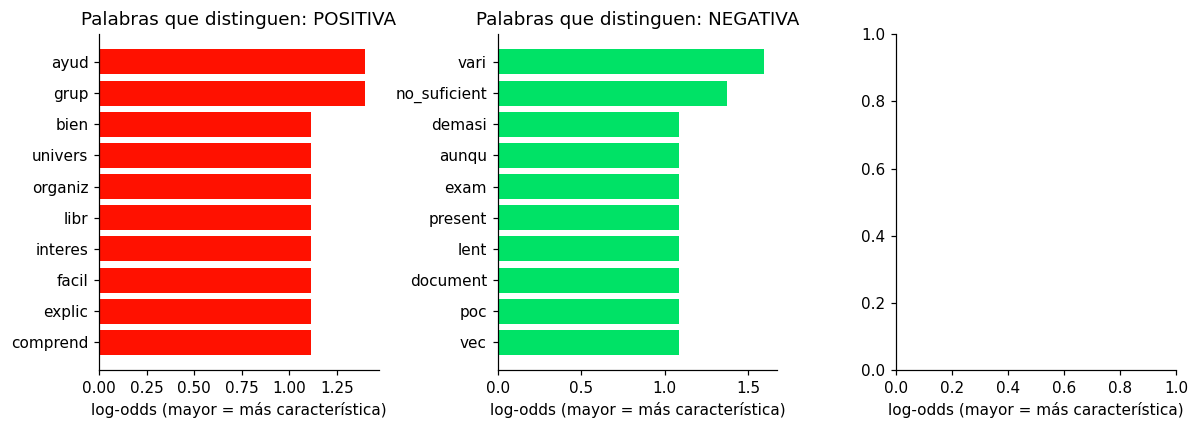

,clase,termino,frec_positiva,frec_negativa,log_odds_pos_vs_neg
0,positiva,ayud,3,0,1.40
1,positiva,grup,3,0,1.40
2,positiva,bien,2,0,1.11
3,positiva,univers,2,0,1.11
4,positiva,organiz,2,0,1.11
5,positiva,libr,2,0,1.11
6,positiva,interes,2,0,1.11
7,positiva,facil,2,0,1.11
8,positiva,explic,2,0,1.11
9,positiva,comprend,2,0,1.11


In [ ]:
# ¿Qué palabras distinguen a las categorías? -> diferencia de frecuencia relativa (log-odds suavizado)
cats = list(np.unique(y_train))        # ['negativa', 'positiva', 'consulta']
frec = {c: np.asarray(X_train_bow[(y_train == c).values].sum(axis=0)).ravel() for c in cats}
tot  = {c: frec[c].sum() for c in cats}
a = 1.0  # suavizado de Laplace
lo = np.log((frec["positiva"] + a) / (tot["positiva"] + a * n_terms)) - \
     np.log((frec["negativa"] + a) / (tot["negativa"] + a * n_terms))
disc = pd.DataFrame({"termino": vocab, "log_odds_pos_vs_neg": lo,
                     "frec_positiva": frec["positiva"], "frec_negativa": frec["negativa"], "frec_consulta": frec["consulta"]})
disc["frec_total"] = disc.frec_positiva + disc.frec_negativa + disc.frec_consulta
disc_f = disc[disc.frec_total >= 2] if (disc.frec_total >= 2).sum() >= 20 else disc

top_pos = disc_f.sort_values("log_odds_pos_vs_neg", ascending=False).head(10)
top_neg = disc_f.sort_values("log_odds_pos_vs_neg").head(10)
top_consulta = disc_f.sort_values("frec_consulta", ascending=False).head(10)

fig, ax = plt.subplots(1, 3, figsize=(11, 4))
ax[0].barh(top_pos.termino[::-1], top_pos.log_odds_pos_vs_neg[::-1], color=colores["positiva"])
ax[0].set_title("Palabras que distinguen: POSITIVA")
ax[1].barh(top_neg.termino[::-1], -top_neg.log_odds_pos_vs_neg[::-1], color=colores["negativa"])
ax[1].set_title("Palabras que distinguen: NEGATIVA")
ax[2].barh(top_consulta.termino[::-1], top_consulta.frec_consulta[::-1], color=colores["consulta"])
ax[2].set_title("Palabras más frecuentes: CONSULTA")
for a_ in ax: a_.set_xlabel("log-odds (mayor = más característica)")
plt.tight_layout(); plt.show()
display(pd.concat([top_pos.assign(clase="positiva"), top_neg.assign(clase="negativa"), top_consulta.assign(clase="consulta")])
        [["clase", "termino", "frec_positiva", "frec_negativa", "frec_consulta", "log_odds_pos_vs_neg"]].round(2).reset_index(drop=True))

## 2.2 TF-IDF
Asigna **más peso** a los términos característicos de un documento y **menos** a los que aparecen en muchos documentos.

$$\text{tf-idf}(t,d)=\text{tf}(t,d)\cdot \text{idf}(t),\qquad \text{idf}(t)=\ln\frac{1+n}{1+\text{df}(t)}+1$$

(`scikit-learn` usa esta versión suavizada y luego normaliza cada vector con la norma L2).

In [ ]:
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)
assert list(tfidf.get_feature_names_out()) == list(vocab)   # mismo vocabulario que BoW

print(f"Matriz TF-IDF (entrenamiento): {X_train_tfidf.shape} | (prueba): {X_test_tfidf.shape}")

# --- Tabla pedida: al menos 5 términos con sus pesos para algunos documentos ---
def tabla_pesos(i, n=6):
    fila = X_train_tfidf[i].toarray().ravel()
    idx = np.argsort(-fila)[:n]
    return pd.DataFrame({
        "documento": f"doc{i} [{y_train.iloc[i]}]",
        "termino": vocab[idx],
        "frecuencia_BoW": X_train_bow[i].toarray().ravel()[idx],
        "idf": tfidf.idf_[idx].round(3),
        "peso_TFIDF": fila[idx].round(3),
    })

pesos = pd.concat([tabla_pesos(i) for i in range(3)], ignore_index=True)
pesos

In [ ]:
# Verificación manual de la fórmula con un término del doc0
i, t = 0, pesos.iloc[0]["termino"]
j = list(vocab).index(t)
df_t = int((X_train_bow[:, j] > 0).sum())
idf_manual = np.log((1 + n_docs) / (1 + df_t)) + 1
print(f"Término «{t}»: aparece en {df_t} de {n_docs} documentos")
print(f"  idf manual = ln((1+{n_docs})/(1+{df_t})) + 1 = {idf_manual:.4f}  |  idf sklearn = {tfidf.idf_[j]:.4f}")
fila_cruda = X_train_bow[i].toarray().ravel() * tfidf.idf_          # tf * idf (sin normalizar)
peso_manual = fila_cruda[j] / np.linalg.norm(fila_cruda)             # normalización L2
print(f"  peso manual = {peso_manual:.4f}  |  peso sklearn = {X_train_tfidf[i, j]:.4f}")
assert np.isclose(peso_manual, X_train_tfidf[i, j])

In [ ]:
# Términos con menor y mayor IDF (comunes vs. raros)
idf_df = pd.DataFrame({"termino": vocab, "idf": tfidf.idf_, "docs_con_el_termino": np.asarray((X_train_bow > 0).sum(axis=0)).ravel()})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
bajo = idf_df.sort_values("idf").head(10); alto = idf_df.sort_values("idf", ascending=False).head(10)
ax[0].barh(bajo.termino[::-1], bajo.idf[::-1], color="#6c757d"); ax[0].set_title("10 términos con IDF más BAJO (comunes)")
ax[1].barh(alto.termino[::-1], alto.idf[::-1], color="#264653"); ax[1].set_title("10 términos con IDF más ALTO (raros)")
plt.tight_layout(); plt.show()

### Interpretación (pregunta crítica 1)
Si una palabra aparece en casi todos los comentarios, su **IDF es cercano al mínimo** y, por tanto, su peso TF-IDF es bajo. Eso **no significa que carezca de importancia semántica**: significa que **no ayuda a distinguir un comentario de otro** (poder discriminante bajo). Una palabra como *universidad* puede ser esencial para el tema, pero no para separar positivos de negativos. BoW, en cambio, la contaría con el mismo peso que cualquier otra y puede dominar el vector.

---
# FASE 3 — Reducción de dimensionalidad con PCA
**Rúbrica: PCA (15 pts)** → gráfico, varianza explicada e interpretación.

El PCA se ajusta **solo con `X_train_tfidf`**; el conjunto de prueba se proyecta con la misma transformación. Con ~100 comentarios la matriz densa es pequeña, por lo que se puede usar `PCA` clásico.

In [ ]:
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score

Xtr_d = X_train_tfidf.toarray()
Xte_d = X_test_tfidf.toarray()

pca_full = PCA(random_state=SEMILLA).fit(Xtr_d)          # ajustado SOLO con entrenamiento
var = pca_full.explained_variance_ratio_
acum = np.cumsum(var)

tabla_var = pd.DataFrame({"componente": [f"PC{i+1}" for i in range(len(var))],
                          "varianza_explicada_%": (var * 100).round(2),
                          "varianza_acumulada_%": (acum * 100).round(2)})
print("Varianza explicada por componente (primeros 10):")
display(tabla_var.head(10))

n80, n90 = int(np.argmax(acum >= .80) + 1), int(np.argmax(acum >= .90) + 1)
print(f"Dimensión original: {Xtr_d.shape[1]} términos")
print(f"Componentes para conservar 80% de la varianza: {n80} | 90%: {n90}")
print(f"Con solo 2 componentes se conserva: {acum[1]:.1%} de la variabilidad")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
m_ = min(20, len(var))
ax[0].bar(range(1, m_ + 1), var[:m_] * 100, color="#457b9d")
ax[0].set_title("Varianza explicada por componente"); ax[0].set_xlabel("Componente"); ax[0].set_ylabel("%")
ax[1].plot(range(1, len(acum) + 1), acum * 100, color="#e76f51")
ax[1].axhline(90, ls="--", c="gray"); ax[1].axhline(80, ls=":", c="gray")
ax[1].set_title("Varianza acumulada"); ax[1].set_xlabel("Nº de componentes"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

In [ ]:
pca2 = PCA(n_components=2, random_state=SEMILLA).fit(Xtr_d)
Z_train, Z_test = pca2.transform(Xtr_d), pca2.transform(Xte_d)

fig, ax = plt.subplots(figsize=(7.5, 6))
for c in cats:
    m = (y_train == c).values
    ax.scatter(Z_train[m, 0], Z_train[m, 1], c=colores[c], s=55, alpha=.75, edgecolor="white", label=f"{c} (train)")
    m2 = (y_test == c).values
    ax.scatter(Z_test[m2, 0], Z_test[m2, 1], c=colores[c], s=90, marker="^", edgecolor="black", label=f"{c} (test)")
ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})")
ax.set_title("Comentarios en 2 componentes principales (TF-IDF)")
ax.legend(); plt.tight_layout(); plt.show()

# Términos que más pesan en cada componente
def top_cargas(comp, n=6):
    idx = np.argsort(-np.abs(pca2.components_[comp]))[:n]
    return ", ".join(f"{vocab[i]} ({pca2.components_[comp][i]:+.2f})" for i in idx)
print("PC1 ← ", top_cargas(0)); print("PC2 ← ", top_cargas(1))

In [ ]:
# Comparación con la representación original: ¿qué tan separadas están las clases?
sil_orig = silhouette_score(Xtr_d, y_train)                 # 400+ dimensiones
sil_2d   = silhouette_score(Z_train, y_train)               # 2 componentes
n_sil    = max(n80, 2)
Z_n      = PCA(n_components=n_sil, random_state=SEMILLA).fit(Xtr_d).transform(Xtr_d)
sil_n    = silhouette_score(Z_n, y_train)

comp = pd.DataFrame({"representación": ["TF-IDF original", f"PCA {n_sil} comp. (≥80% var.)", "PCA 2 comp."],
                     "dimensiones": [Xtr_d.shape[1], n_sil, 2],
                     "silhouette (por categoría)": [sil_orig, sil_n, sil_2d]}).round(3)
display(comp)

# Contraste con TruncatedSVD (alternativa para matrices dispersas, sin centrar)
svd = TruncatedSVD(n_components=2, random_state=SEMILLA).fit(X_train_tfidf)
print(f"TruncatedSVD (2 comp.) varianza explicada: {svd.explained_variance_ratio_.sum():.1%} "
      f"vs PCA 2 comp.: {acum[1]:.1%}")

separa = sil_2d > 0.10
print("\nLECTURA AUTOMÁTICA DEL GRÁFICO:")
print(f"- Silhouette en 2D = {sil_2d:.3f} → " + ("las categorías muestran separación parcial." if separa
      else "las categorías se MEZCLAN en el plano de 2 componentes (silhouette cercano a 0)."))
print(f"- Los 2 primeros componentes solo retienen {acum[1]:.1%} de la variabilidad: la mayor parte de la "
      "información está en las otras dimensiones.")

### Interpretación del PCA (preguntas críticas 3)
- **Si las clases se mezclan en 2D, ¿ningún clasificador podrá separarlas? No.** El gráfico solo muestra una proyección que conserva el *pequeño* porcentaje de varianza indicado arriba. La separabilidad puede existir en las demás dimensiones (el SVM trabaja en el espacio completo).
- PCA es **no supervisado**: maximiza la varianza, no la separación entre categorías. Un componente de alta varianza puede reflejar el *tema* del comentario (biblioteca, inscripción, docentes) y no su polaridad.
- En textos, la matriz es dispersa y de alta dimensión; la varianza se reparte en muchos componentes (curva acumulada lenta). Por eso se usa **como análisis exploratorio** y se comprueba en la Fase 4 si incluirlo mejora o no el modelo.

---
# FASE 4 — Entrenamiento y comparación de los cuatro clasificadores
**Rúbrica: Naive Bayes y SVM (20 pts).**

Modelos: **BoW+NB**, **TF-IDF+NB**, **BoW+SVM**, **TF-IDF+SVM**. Cada uno es un `Pipeline` (vectorizador → clasificador) para que el ajuste del vocabulario ocurra *solo con los datos de entrenamiento* también dentro de la validación cruzada. Los hiperparámetros se eligen con `GridSearchCV` **sobre el entrenamiento**; el test solo se usa al final.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import time

n_splits = int(min(5, y_train.value_counts().min()))
cv_inner = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEMILLA)
print(f"Validación cruzada interna: {n_splits} pliegues estratificados")

vec_grid = {"vec__ngram_range": [(1, 1), (1, 2)], "vec__min_df": [1, 2]}
configs = {
    "BoW + Naive Bayes":    (CountVectorizer(),  MultinomialNB(),                          {**vec_grid, "clf__alpha": [0.1, 0.3, 0.5, 1.0]}),
    "TF-IDF + Naive Bayes": (TfidfVectorizer(),  MultinomialNB(),                          {**vec_grid, "clf__alpha": [0.1, 0.3, 0.5, 1.0]}),
    "BoW + SVM":            (CountVectorizer(),  SVC(class_weight="balanced"),             {**vec_grid, "clf__C": [0.1, 1, 10], "clf__kernel": ["linear", "rbf"]}),
    "TF-IDF + SVM":         (TfidfVectorizer(),  SVC(class_weight="balanced"),             {**vec_grid, "clf__C": [0.1, 1, 10], "clf__kernel": ["linear", "rbf"]}),
}

modelos, mejores_params = {}, {}
for nombre, (vec, clf, grid) in configs.items():
    t0 = time.time()
    gs = GridSearchCV(Pipeline([("vec", vec), ("clf", clf)]), grid, scoring="f1_macro", cv=cv_inner, n_jobs=-1)
    gs.fit(X_train, y_train)                      # <- solo entrenamiento
    modelos[nombre] = gs.best_estimator_
    mejores_params[nombre] = {"F1 macro (CV train)": round(gs.best_score_, 3), **{k.split("__")[1]: v for k, v in gs.best_params_.items()}}
    print(f"✔ {nombre:22s} F1-CV={gs.best_score_:.3f}  ({time.time()-t0:.1f}s)")

pd.DataFrame(mejores_params).T

## 4.1 Naive Bayes: cómo usa las probabilidades de las palabras

Naive Bayes aplica el teorema de Bayes con el supuesto «ingenuo» de que las palabras son **independientes dado la clase**:

$$P(c\mid d)\ \propto\ P(c)\prod_{w\in d}P(w\mid c)^{n_{w,d}}\quad\Rightarrow\quad \log P(c\mid d)=\log P(c)+\sum_w n_{w,d}\,\log P(w\mid c)$$

Se calcula esto para cada clase y se asigna la de **mayor probabilidad a posteriori**. Se verifica a mano con un comentario del test.

In [ ]:
nb_pipe = modelos["BoW + Naive Bayes"]
vec_nb, nb = nb_pipe.named_steps["vec"], nb_pipe.named_steps["clf"]

# --- Cálculo manual del posterior para un comentario de prueba ---
doc = X_test.iloc[0]
x = vec_nb.transform([doc])
logpost = nb.class_log_prior_ + x @ nb.feature_log_prob_.T          # log P(c) + Σ n·log P(w|c)
logpost = np.asarray(logpost).ravel()
post = np.exp(logpost - logpost.max()); post /= post.sum()
print(f"Comentario: «{test_df[COL_TEXTO].iloc[0]}»   (real: {y_test.iloc[0]})")
print(f"Procesado:  {doc}")
for c, lp, p in zip(nb.classes_, logpost, post):
    print(f"  clase {c:9s} | log P(c)={nb.class_log_prior_[list(nb.classes_).index(c)]:.3f} | log-posterior={lp:.3f} | P(c|d)={p:.3f}")
assert np.allclose(post, nb_pipe.predict_proba([doc])[0]), "El cálculo manual no coincide con sklearn"
print("✔ Coincide con predict_proba de scikit-learn → predicción:", nb_pipe.predict([doc])[0])

# --- Palabras con mayor probabilidad por clase ---
terminos = vec_nb.get_feature_names_out()
dif = nb.feature_log_prob_[list(nb.classes_).index("positiva")] - nb.feature_log_prob_[list(nb.classes_).index("negativa")]
orden = np.argsort(dif)
print("\nPalabras que MÁS inclinan hacia NEGATIVA:", ", ".join(terminos[orden[:8]]))
print("Palabras que MÁS inclinan hacia POSITIVA:", ", ".join(terminos[orden[::-1][:8]]))

## 4.2 SVM: frontera de decisión (explicación conceptual)

Un SVM busca el **hiperplano** $w\cdot x+b=0$ que separa las clases con el **máximo margen**. Solo los **vectores de soporte** (los puntos más cercanos a la frontera) la determinan. Con datos no separables linealmente, el parámetro `C` regula el compromiso entre margen ancho y errores, y un *kernel* (RBF) permite fronteras no lineales. En texto de alta dimensión el kernel lineal suele bastar. La siguiente figura **ilustra** la idea en el plano de 2 componentes (solo con fines conceptuales; los modelos reales se entrenan en el espacio completo).

In [ ]:
# Ilustración 2D: SVM lineal sobre las 2 primeras componentes (solo entrenamiento)
ytr_num = (y_train == "positiva").astype(int).values
svm2d = SVC(kernel="linear", C=1.0).fit(Z_train, ytr_num)
xx, yy = np.meshgrid(np.linspace(Z_train[:, 0].min() - .1, Z_train[:, 0].max() + .1, 300),
                     np.linspace(Z_train[:, 1].min() - .1, Z_train[:, 1].max() + .1, 300))
dfun = svm2d.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.contourf(xx, yy, dfun, levels=[-99, 0, 99], colors=[colores["negativa"], colores["positiva"]], alpha=.12)
ax.contour(xx, yy, dfun, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
for c in cats:
    m = (y_train == c).values
    ax.scatter(Z_train[m, 0], Z_train[m, 1], c=colores[c], s=50, edgecolor="white", label=c)
ax.scatter(*svm2d.support_vectors_.T, s=170, facecolors="none", edgecolors="k", linewidths=1.5, label="vectores de soporte")
ax.set_title("Frontera (línea continua) y margen (discontinuas) de un SVM lineal en 2D")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Vectores de soporte: {len(svm2d.support_)} de {len(Z_train)} puntos de entrenamiento")

In [ ]:
# Interpretación en el espacio completo: SVM lineal sobre TF-IDF (modelo auxiliar de interpretación)
aux = Pipeline([("vec", TfidfVectorizer()), ("clf", LinearSVC(C=1.0, class_weight="balanced", random_state=SEMILLA))]).fit(X_train, y_train)
terms_aux = aux.named_steps["vec"].get_feature_names_out()
coef = aux.named_steps["clf"].coef_.ravel()          # >0 -> 'positiva' (clases ordenadas: negativa, positiva)
o = np.argsort(coef)
print("Términos con coeficiente más NEGATIVO (empujan a 'negativa'):", ", ".join(terms_aux[o[:8]]))
print("Términos con coeficiente más POSITIVO (empujan a 'positiva'):", ", ".join(terms_aux[o[::-1][:8]]))

## 4.3 Evaluación de los cuatro modelos con el **mismo** conjunto de prueba

In [ ]:
def metricas(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "Recall negativa": recall_score(y_true, y_pred, pos_label="negativa", average="binary", zero_division=0),
            "Precision negativa": precision_score(y_true, y_pred, pos_label="negativa", average="binary", zero_division=0)}

pred_test = {n: m.predict(X_test) for n, m in modelos.items()}
res = pd.DataFrame({n: metricas(y_test, p) for n, p in pred_test.items()}).T
res.insert(0, "Clasificador", [n.split(" + ")[1] for n in res.index])
res.insert(0, "Representación", [n.split(" + ")[0] for n in res.index])

print(f"Conjunto de prueba: {len(y_test)} comentarios (idéntico para los 4 modelos)\n")
tabla_final = res[["Representación", "Clasificador", "Accuracy", "F1 macro"]].round(3).reset_index(drop=True)
display(tabla_final)
print("Métricas completas:")
display(res.drop(columns=["Representación", "Clasificador"]).round(3))

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (n, p) in zip(axs, pred_test.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p, labels=["negativa", "positiva"]),
                           display_labels=["negativa", "positiva"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{n}\nAcc={accuracy_score(y_test, p):.2f}", fontsize=10)
plt.tight_layout(); plt.show()

for n, p in pred_test.items():
    print(f"\n=== {n} ===")
    print(classification_report(y_test, p, zero_division=0))

## 4.4 ¿PCA mejora el clasificador? (experimento complementario)
El enunciado advierte que PCA puede reducir dimensiones pero no necesariamente mejora la clasificación. Se comprueba: TF-IDF → PCA (≥80 % de varianza, ajustado dentro del `Pipeline`, solo con entrenamiento) → SVM.

In [ ]:
from sklearn.preprocessing import FunctionTransformer
dens = FunctionTransformer(lambda m: m.toarray(), accept_sparse=True)
mejor_vec_params = {k.replace("vec__", ""): v for k, v in
                    {"ngram_range": modelos["TF-IDF + SVM"].named_steps["vec"].ngram_range,
                     "min_df": modelos["TF-IDF + SVM"].named_steps["vec"].min_df}.items()}
pipe_pca = Pipeline([("vec", TfidfVectorizer(**mejor_vec_params)), ("dens", dens),
                     ("pca", PCA(n_components=0.80, svd_solver="full", random_state=SEMILLA)),
                     ("clf", SVC(kernel="linear", C=1, class_weight="balanced"))]).fit(X_train, y_train)
p_pca = pipe_pca.predict(X_test)
print(f"Componentes retenidos (80% var.): {pipe_pca.named_steps['pca'].n_components_}")
print(f"TF-IDF + PCA + SVM → Accuracy={accuracy_score(y_test, p_pca):.3f} | F1 macro={f1_score(y_test, p_pca, average='macro'):.3f}")
print(f"TF-IDF + SVM       → Accuracy={res.loc['TF-IDF + SVM','Accuracy']:.3f} | F1 macro={res.loc['TF-IDF + SVM','F1 macro']:.3f}")

## 4.5 Robustez: validación cruzada estratificada repetida (5×3)
Con un conjunto de prueba pequeño, una sola partición puede favorecer a un modelo por azar. Se evalúan los 4 modelos (con los hiperparámetros ya elegidos) sobre **los mismos 15 pliegues** del corpus completo. Esto responde la pregunta 7: al usar particiones idénticas, la diferencia entre BoW y TF-IDF **no se debe a una partición distinta**.

In [ ]:
n_spl = int(min(5, df[COL_ETIQUETA].value_counts().min()))
cv_rep = RepeatedStratifiedKFold(n_splits=n_spl, n_repeats=3, random_state=SEMILLA)
X_all, y_all = df["texto_proc"], df[COL_ETIQUETA]
scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro", "recall_neg": "recall"}

from sklearn.metrics import make_scorer
scoring["recall_neg"] = make_scorer(recall_score, pos_label="negativa", average="binary", zero_division=0)

cv_res = {n: cross_validate(clone(m), X_all, y_all, cv=cv_rep, scoring=scoring, n_jobs=-1) for n, m in modelos.items()}
cv_tab = pd.DataFrame({n: {"Accuracy (media)": r["test_accuracy"].mean(), "Accuracy (±)": r["test_accuracy"].std(),
                           "F1 macro (media)": r["test_f1_macro"].mean(), "F1 macro (±)": r["test_f1_macro"].std(),
                           "Recall negativa (media)": r["test_recall_neg"].mean()} for n, r in cv_res.items()}).T
display(cv_tab.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.boxplot([cv_res[n]["test_f1_macro"] for n in modelos], showmeans=True)
ax.set_xticklabels(list(modelos))
ax.set_ylabel("F1 macro por pliegue"); ax.set_title(f"Validación cruzada {n_spl}×3 (mismos pliegues para todos)")
plt.xticks(rotation=12); plt.tight_layout(); plt.show()

# Comparación pareada (mismos pliegues): TF-IDF − BoW dentro de cada clasificador
for clf_ in ["Naive Bayes", "SVM"]:
    d = cv_res[f"TF-IDF + {clf_}"]["test_f1_macro"] - cv_res[f"BoW + {clf_}"]["test_f1_macro"]
    print(f"{clf_:12s}: TF-IDF − BoW = {d.mean():+.3f} (±{d.std():.3f}) | TF-IDF mejor en {(d > 0).sum()}/{len(d)} pliegues, empata en {(d == 0).sum()}")
for rep in ["BoW", "TF-IDF"]:
    d = cv_res[f"{rep} + SVM"]["test_f1_macro"] - cv_res[f"{rep} + Naive Bayes"]["test_f1_macro"]
    print(f"{rep:7s}: SVM − NB = {d.mean():+.3f} (±{d.std():.3f}) | SVM mejor en {(d > 0).sum()}/{len(d)} pliegues, empata en {(d == 0).sum()}")

---
# FASE 5 — Análisis crítico
**Rúbrica: Evaluación y análisis crítico (20 pts)** → métricas, errores y justificación del modelo.

## 5.1 Revisión de los errores de clasificación

In [ ]:
NEGAD_TXT = re.compile(r"\b(no|nunca|jam[aá]s|tampoco|sin|ni)\b", re.I)
vocab_train = set(vocab)

def hipotesis(texto_original, texto_proc):
    h = []
    toks = texto_proc.split()
    if NEGAD_TXT.search(texto_original): h.append("negación")
    if re.search(r"\b(pero|aunque|sino)\b", texto_original, re.I): h.append("contraste (pero/aunque)")
    if toks and sum(t not in vocab_train for t in toks) / len(toks) > .30: h.append("vocabulario nuevo")
    if len(toks) <= 3: h.append("texto muy corto")
    if re.search(r"[!?]{2,}|[A-ZÁÉÍÓÚ]{4,}", texto_original): h.append("énfasis/mayúsculas")
    return ", ".join(h) if h else "sin patrón evidente (¿ironía o etiqueta ambigua?)"

nombres = list(modelos)
errores = test_df[[COL_TEXTO, COL_ETIQUETA, "texto_proc"]].copy()
for n in nombres:
    errores[n] = pred_test[n]
errores["modelos_que_fallan"] = sum((errores[n] != errores[COL_ETIQUETA]).astype(int) for n in nombres)
err_test = errores[errores.modelos_que_fallan > 0].sort_values("modelos_que_fallan", ascending=False).copy()
err_test["hipótesis_de_causa"] = [hipotesis(a, b) for a, b in zip(err_test[COL_TEXTO], err_test["texto_proc"])]

if len(err_test):
    print(f"Comentarios de prueba mal clasificados por al menos un modelo: {len(err_test)} de {len(test_df)}")
    display(err_test.drop(columns=["texto_proc"]).reset_index(drop=True))
else:
    print("Ningún modelo falló en el conjunto de prueba (¡revisar con la validación cruzada de abajo!).")

In [ ]:
# Con un test pequeño hay pocos errores: se revisan también los errores "fuera de muestra" (out-of-fold) del corpus completo
mejor_cv_nombre = cv_tab["F1 macro (media)"].idxmax()
oof = cross_val_predict(clone(modelos[mejor_cv_nombre]), X_all, y_all, cv=StratifiedKFold(n_spl, shuffle=True, random_state=SEMILLA))
mal = df.loc[oof != y_all.values, [COL_TEXTO, COL_ETIQUETA, "texto_proc"]].copy()
mal["predicho"] = oof[oof != y_all.values]
mal["hipótesis_de_causa"] = [hipotesis(a, b) for a, b in zip(mal[COL_TEXTO], mal["texto_proc"])]
print(f"Errores out-of-fold del mejor modelo en CV ({mejor_cv_nombre}): {len(mal)} de {len(df)} ({len(mal)/len(df):.1%})")
display(mal.drop(columns=["texto_proc"]).reset_index(drop=True).head(15))

if len(mal):
    fn = ((mal[COL_ETIQUETA] == "negativa") & (mal["predicho"] == "positiva")).sum()
    fp = ((mal[COL_ETIQUETA] == "positiva") & (mal["predicho"] == "negativa")).sum()
    print(f"Negativos clasificados como positivos (error más costoso): {fn} | Positivos clasificados como negativos: {fp}")

**Consecuencias de los errores (pregunta crítica 4):** un comentario **negativo clasificado como positivo** es el error más grave en este contexto, porque una queja que requería atención prioritaria queda sin atender. Un positivo clasificado como negativo genera trabajo innecesario, pero no pierde información crítica. Por eso se vigila especialmente el **recall de la clase negativa**.

## 5.2 Prueba con cinco comentarios nuevos

In [ ]:
from sklearn.calibration import CalibratedClassifierCV

# Mejor representación por familia, según F1 macro en validación cruzada
mejor_nb  = max(["BoW + Naive Bayes", "TF-IDF + Naive Bayes"], key=lambda n: cv_tab.loc[n, "F1 macro (media)"])
mejor_svm = max(["BoW + SVM", "TF-IDF + SVM"], key=lambda n: cv_tab.loc[n, "F1 macro (media)"])
print("Mejor NB :", mejor_nb, "| Mejor SVM:", mejor_svm)

# Probabilidades calibradas para el SVM (Platt), solo para medir confianza
try:
    svm_cal = CalibratedClassifierCV(clone(modelos[mejor_svm]), method="sigmoid", cv=min(3, n_splits)).fit(X_train, y_train)
except Exception as e:
    svm_cal = None; print("No se pudo calibrar el SVM:", e)

def preparar(txt):
    return limpiar_texto(txt, stem=True, marcar_negacion=True)

def predecir_todo(textos):
    proc = [preparar(t) for t in textos]
    filas = []
    for t, p in zip(textos, proc):
        fila = {"comentario": t}
        for n, m in modelos.items():
            fila[n] = m.predict([p])[0]
        pn = modelos[mejor_nb].predict_proba([p])[0]
        fila["conf_NB"] = pn.max()
        if svm_cal is not None:
            fila["conf_SVM"] = svm_cal.predict_proba([p])[0].max()
        else:
            fila["conf_SVM"] = np.nan
        fila["acuerdo_NB_SVM"] = "sí" if fila[mejor_nb] == fila[mejor_svm] else "NO"
        fila["más_confiable"] = ("NB" if fila["conf_NB"] >= fila["conf_SVM"] else "SVM") if not np.isnan(fila["conf_SVM"]) else "NB"
        filas.append(fila)
    return pd.DataFrame(filas)

NUEVOS = [   # <-- reemplázalos por comentarios propios si lo deseas
    ("Excelente atención en la biblioteca, el personal fue muy amable y rápido.", "positiva"),   # claro positivo
    ("Pésimo servicio, llevo tres semanas esperando una respuesta y nadie me atiende.", "negativa"), # claro negativo
    ("No me gustó nada cómo explican los profesores, no se entiende.", "negativa"),             # con negación
    ("Qué maravilla, otra vez sin internet en el laboratorio, justo lo que necesitaba.", "negativa"),  # ironía
    ("xq la inscrip es tan lenta, ntp pero deberian mejorarla!!!", "negativa"),                 # jerga / ortografía
]
nuevos_df = predecir_todo([t for t, _ in NUEVOS])
nuevos_df.insert(1, "esperada", [e for _, e in NUEVOS])
pd.set_option("display.width", 250)
display(nuevos_df[["comentario", "esperada"] + nombres + ["conf_NB", "conf_SVM", "acuerdo_NB_SVM", "más_confiable"]].round(3))
for nme in nombres:
    print(f"{nme:22s}: {(nuevos_df[nme] == nuevos_df['esperada']).sum()}/5 aciertos")

> **Lectura:** los casos con **ironía** (comentario 4) son el punto débil esperado de los modelos de bolsa de palabras: las palabras positivas ("maravilla", "necesitaba") pesan más que el sentido real de la frase. La **confianza** de NB (probabilidad) y del SVM (probabilidad calibrada con Platt) permite señalar qué comentarios conviene revisar a mano cuando los dos modelos **no coinciden** o la confianza es baja.

## 5.3 Comparación por comentario: ¿qué modelo aplica mejor?

In [ ]:
# En el conjunto de prueba (la etiqueta real SÍ se conoce): qué familia acierta en cada comentario
cmp = test_df[[COL_TEXTO, COL_ETIQUETA]].copy()
cmp["pred_NB"], cmp["pred_SVM"] = pred_test[mejor_nb], pred_test[mejor_svm]
cmp["acierta_NB"], cmp["acierta_SVM"] = cmp.pred_NB == cmp[COL_ETIQUETA], cmp.pred_SVM == cmp[COL_ETIQUETA]
cmp["conf_NB"] = modelos[mejor_nb].predict_proba(X_test).max(axis=1)
cmp["conf_SVM"] = svm_cal.predict_proba(X_test).max(axis=1) if svm_cal is not None else np.nan

def mejor_aplica(r):
    if r.acierta_NB and r.acierta_SVM:         return "ambos aciertan"
    if r.acierta_NB and not r.acierta_SVM:     return "Naive Bayes"
    if r.acierta_SVM and not r.acierta_NB:     return "SVM"
    return "ninguno"
cmp["modelo_que_aplica_mejor"] = [mejor_aplica(r) for r in cmp.itertuples()]

display(cmp[cmp.modelo_que_aplica_mejor != "ambos aciertan"].round(3).reset_index(drop=True)
        if (cmp.modelo_que_aplica_mejor != "ambos aciertan").any() else pd.DataFrame({"resultado": ["Ambos modelos aciertan en todos los comentarios de prueba"]}))
print(cmp.modelo_que_aplica_mejor.value_counts().to_string())

## 5.4 Elección del modelo y justificación

In [ ]:
rank = cv_tab[["F1 macro (media)", "F1 macro (±)", "Accuracy (media)", "Recall negativa (media)"]].join(res[["F1 macro", "Recall negativa"]].rename(columns={"F1 macro": "F1 macro (test)", "Recall negativa": "Recall neg. (test)"}))
rank = rank.sort_values(["F1 macro (media)", "Recall negativa (media)"], ascending=False)
display(rank.round(3))

ganador = rank.index[0]
segundo = rank.index[1]
dif = rank.iloc[0]["F1 macro (media)"] - rank.iloc[1]["F1 macro (media)"]
sd = max(rank.iloc[0]["F1 macro (±)"], rank.iloc[1]["F1 macro (±)"])
print(f"MODELO ELEGIDO: {ganador}")
print(f"  - F1 macro medio en CV 5x3: {rank.iloc[0]['F1 macro (media)']:.3f} (±{rank.iloc[0]['F1 macro (±)']:.3f})")
print(f"  - Recall de la clase negativa (CV): {rank.iloc[0]['Recall negativa (media)']:.3f}")
print(f"  - Diferencia con el segundo ({segundo}): {dif:+.3f} " + ("→ diferencia menor que la variabilidad entre pliegues: ambos son estadísticamente comparables; se prioriza el que tenga mejor recall negativa y sea más simple/interpretable."
                                                                if dif < sd else "→ ventaja mayor que la variabilidad entre pliegues."))

### Justificación (plantilla a completar con los números de arriba)
Se elige el modelo con **mayor F1 macro medio en validación cruzada repetida**, no el de mayor accuracy en una sola partición, porque (a) el test es pequeño, (b) F1 macro pondera igual a ambas clases y (c) se verifica el **recall de la clase negativa**, que es la de mayor costo de error. Si la diferencia entre los dos mejores es menor que la desviación entre pliegues, se consideran equivalentes y se prefiere el más simple e interpretable (Naive Bayes: rápido y con probabilidades explicables; SVM: más robusto con vocabulario disperso).

## 5.5 Mejoras propuestas
1. **Marcado de negación** (ya aplicado): se comprueba su aporte abajo con un experimento de ablación.
2. **Más datos y diccionario ampliado** con el vocabulario real de la universidad (más ejemplos de ironía y faltas ortográficas).
3. **N-gramas (1,2)** y `min_df`, explorados en la búsqueda de hiperparámetros.
4. **Umbral de revisión humana**: derivar a un operador los comentarios con baja confianza o donde NB y SVM discrepan.
5. **Léxico de polaridad en español** (p. ej. un diccionario propio de palabras positivas/negativas) como característica adicional.

In [ ]:
# Ablación: ¿aporta el stemming + marcado de negación? (mismos pliegues, mismo modelo ganador)
mod_g = clone(modelos[ganador])
F1_proc  = cross_validate(mod_g, df["texto_proc"],   y_all, cv=cv_rep, scoring="f1_macro", n_jobs=-1)["test_score"]
F1_limpio = cross_validate(clone(modelos[ganador]), df["texto_limpio"], y_all, cv=cv_rep, scoring="f1_macro", n_jobs=-1)["test_score"]
print(f"Modelo: {ganador}")
print(f"  Solo limpieza básica (sin stemming ni negación): F1 macro = {F1_limpio.mean():.3f} (±{F1_limpio.std():.3f})")
print(f"  Limpieza + stemming + negación (usado):         F1 macro = {F1_proc.mean():.3f} (±{F1_proc.std():.3f})")
print(f"  Diferencia: {F1_proc.mean() - F1_limpio.mean():+.3f}")

## 5.6 Respuestas a las preguntas de pensamiento crítico

1. **BoW vs TF-IDF.** Una palabra presente en casi todos los comentarios tiene IDF mínimo y, por tanto, peso bajo en TF-IDF: no discrimina entre documentos. Eso **no implica irrelevancia semántica**, solo poco poder para distinguir clases o documentos (ver 2.2).
2. **NB 85 % vs SVM 82 %.** **No se elegiría automáticamente NB.** Se revisarían: F1 macro y recall por clase, la matriz de confusión (qué tipo de error comete cada uno), la variabilidad en validación cruzada repetida (3 puntos pueden ser ruido con un test pequeño), el tamaño de la muestra, la estabilidad ante vocabulario nuevo y el costo de cada error.
3. **PCA mezclado en 2D.** **No** implica que ningún clasificador funcione: dos componentes retienen solo una fracción de la varianza y PCA no busca separar clases. La separabilidad puede estar en las otras dimensiones (ver Fase 3 y 4.4).
4. **Errores.** Negativo → positivo es el más grave (queja no atendida). Consulta → negativa genera priorización innecesaria. Por eso se monitorea el recall de la clase negativa (ver 5.1).
5. **Generalización.** **No.** Acertar en el test solo acredita desempeño sobre comentarios *parecidos* a los de entrenamiento. La ironía, las faltas ortográficas y el vocabulario nuevo (fuera del vocabulario aprendido) degradan el rendimiento; los cinco comentarios nuevos de 5.2 lo ilustran. Hay que probar con datos fuera de muestra y monitorear en producción.
6. **Datos desbalanceados (90 de 120 en una clase).** Un modelo que prediga siempre la clase mayoritaria obtendría 75 % de accuracy sin aprender nada. **Accuracy no basta**: se usan F1 macro, recall/precisión por clase, matriz de confusión, estratificación y `class_weight='balanced'`.
7. **Diseño experimental.** Se compararon BoW y TF-IDF con **los mismos pliegues** (validación cruzada estratificada repetida con semilla fija) y se reportó la diferencia **pareada** por pliegue (ver 4.5); además, el vectorizador se ajusta dentro del `Pipeline` solo con datos de entrenamiento de cada pliegue. Así la mejora no se explica por una partición distinta.

## 5.7 Tabla final y conclusión

In [ ]:
final = res[["Representación", "Clasificador", "Accuracy", "F1 macro"]].copy()
final["F1 macro CV (media ± sd)"] = [f"{cv_tab.loc[n, 'F1 macro (media)']:.3f} ± {cv_tab.loc[n, 'F1 macro (±)']:.3f}" for n in final.index]
final["Recall negativa (test)"] = res["Recall negativa"].values
final = final.round(3).reset_index(drop=True)
display(final)

print(f'''
CONCLUSIÓN
  • Representación y clasificador con mejor desempeño promedio: {ganador}.
  • Mejor Naive Bayes: {mejor_nb} | Mejor SVM: {mejor_svm}.
  • La elección se basa en F1 macro con validación cruzada repetida y en el recall de la clase negativa,
    no solo en el accuracy de una partición.
  • Limitación: corpus pequeño ({len(df)} comentarios); la ironía y el vocabulario nuevo siguen siendo difíciles.
''')

## 5.8 Exportación de artefactos (para el dashboard de la defensa)

In [ ]:
joblib.dump(modelos, DIR_ARTEFACTOS / "modelos.joblib")
joblib.dump(svm_cal, DIR_ARTEFACTOS / "svm_calibrado.joblib")
final.to_csv(DIR_ARTEFACTOS / "tabla_final.csv", index=False)
res.to_csv(DIR_ARTEFACTOS / "metricas_test.csv")
cv_tab.to_csv(DIR_ARTEFACTOS / "metricas_cv.csv")
cmp.to_csv(DIR_ARTEFACTOS / "comparacion_por_comentario.csv", index=False)
nuevos_df.to_csv(DIR_ARTEFACTOS / "cinco_nuevos.csv", index=False)
joblib.dump({"mejor_nb": mejor_nb, "mejor_svm": mejor_svm, "ganador": ganador,
             "pca_var": var, "Z_train": Z_train, "Z_test": Z_test, "y_train": y_train.values, "y_test": y_test.values,
             "cv_scores": {n: r["test_f1_macro"] for n, r in cv_res.items()}}, DIR_ARTEFACTOS / "resultados_dashboard.joblib")
print("Artefactos exportados en", DIR_ARTEFACTOS.resolve())
print(sorted(p.name for p in DIR_ARTEFACTOS.iterdir()))